# BÁO CÁO THỰC HÀNH PRACTICE 2: PRE-TRAINED MODELS, TRANSFER LEARNING & FINE-TUNING
**Môn học:** Deep Learning (Chương 3: Training Deep Neural Networks)  
**Giảng viên hướng dẫn:** PhD. Nguyễn Thị Khánh Tiên  
**Đơn vị:** Trường Đại học Giao thông Vận tải TP.HCM  

---

### Thông tin nhóm sinh viên
- **Nhóm thực hiện:** Nhóm 1  
- **Thành viên 1:** [SV điền: Họ và tên 1] — MSSV: [SV điền: MSSV 1]  
- **Thành viên 2:** [SV điền: Họ và tên 2] — MSSV: [SV điền: MSSV 2]  
- **Thành viên 3:** [SV điền: Họ và tên 3] — MSSV: [SV điền: MSSV 3]  

### Mục tiêu thực hành (Objectives từ Slide 23)
1. **Làm quen với Pre-trained Models:** Nạp và sử dụng các kiến trúc mạng nơ-ron tích chập hiện đại từ thư viện chính thức `torchvision.models` với trọng số huấn luyện sẵn trên tập ImageNet.
2. **Hiểu cơ chế thích nghi mô hình (Model Adaptation):**
   - **Transfer Learning (Feature Extraction):** Đóng băng toàn bộ mạng trích xuất đặc trưng (backbone), chỉ huấn luyện lại tầng phân loại (classifier head).
   - **Fine-Tuning:** Đóng băng các tầng biểu diễn đặc trưng cấp thấp ở đầu mạng và mở khóa các khối tích chập sâu nhất cùng với classifier head, áp dụng Differential Learning Rate để tinh chỉnh theo miền dữ liệu mới.
3. **Thực hiện 3 bài tập mở rộng (Practice 2 Exercises):**
   - **Exercise 1:** Thực nghiệm và so sánh đối chứng giữa các kiến trúc pre-trained khác nhau (ResNet18 vs. DenseNet121).
   - **Exercise 2:** Khảo sát tác động khi điều chỉnh các siêu tham số (Learning Rate, Batch Size).
   - **Exercise 3:** Sử dụng công cụ TensorBoard để giám sát trực quan toàn bộ tiến trình huấn luyện.

---

### Mục lục
1. [Bước 1: Thiết lập môi trường và cấu hình (Slide 3)](#1-environment-setup-slide-3)
2. [Bước 2: Nạp mô hình huấn luyện sẵn (Slide 20)](#2-load-a-pre-trained-model-slide-20)
3. [Bước 3: Khảo sát kiến trúc mô hình (Slide 3, 20)](#3-explore-the-model-architecture-slide-3-20)
4. [Bước 4: Thích nghi mô hình cho bài toán mới (Slide 20–21)](#4-adapt-the-model-for-a-specific-task-slide-2021)
5. [Bước 5: Chuẩn bị dữ liệu CIFAR-10 (Slide 4–5)](#5-prepare-the-data-slide-45)
6. [Bước 6: Huấn luyện mô hình (Slide 7–9)](#6-train-the-model-slide-79)
7. [Bước 7: Đánh giá mô hình trên tập Test (Slide 10–11)](#7-evaluate-the-model-slide-1011)
8. [Bài tập 1: So sánh các kiến trúc Pre-trained khác nhau (Slide 23)](#8-exercise-1--different-pre-trained-models-slide-23)
9. [Bài tập 2: Khảo sát điều chỉnh siêu tham số (Slide 23)](#9-exercise-2--hyperparameter-adjustment-slide-23)
10. [Bài tập 3: Giám sát quá trình huấn luyện bằng TensorBoard (Slide 13–15)](#10-exercise-3--tensorboard-monitoring-slide-1315)
11. [Giới hạn kỹ thuật và Hướng phát triển](#11-giới-hạn-kỹ-thuật-và-hướng-phát-triển)
12. [Tài liệu tham khảo](#12-tài-liệu-tham-khảo)

## Sơ đồ Quy trình Thực nghiệm Tổng thể (Lab 2 Pipeline)

Hình dưới đây mô tả chuỗi 6 bước triển khai của toàn bộ dự án, từ tải dữ liệu CIFAR-10 đến sinh báo cáo định lượng.

*(Sơ đồ kỹ thuật — Tạo từ dữ liệu cấu hình thực tế của dự án)*

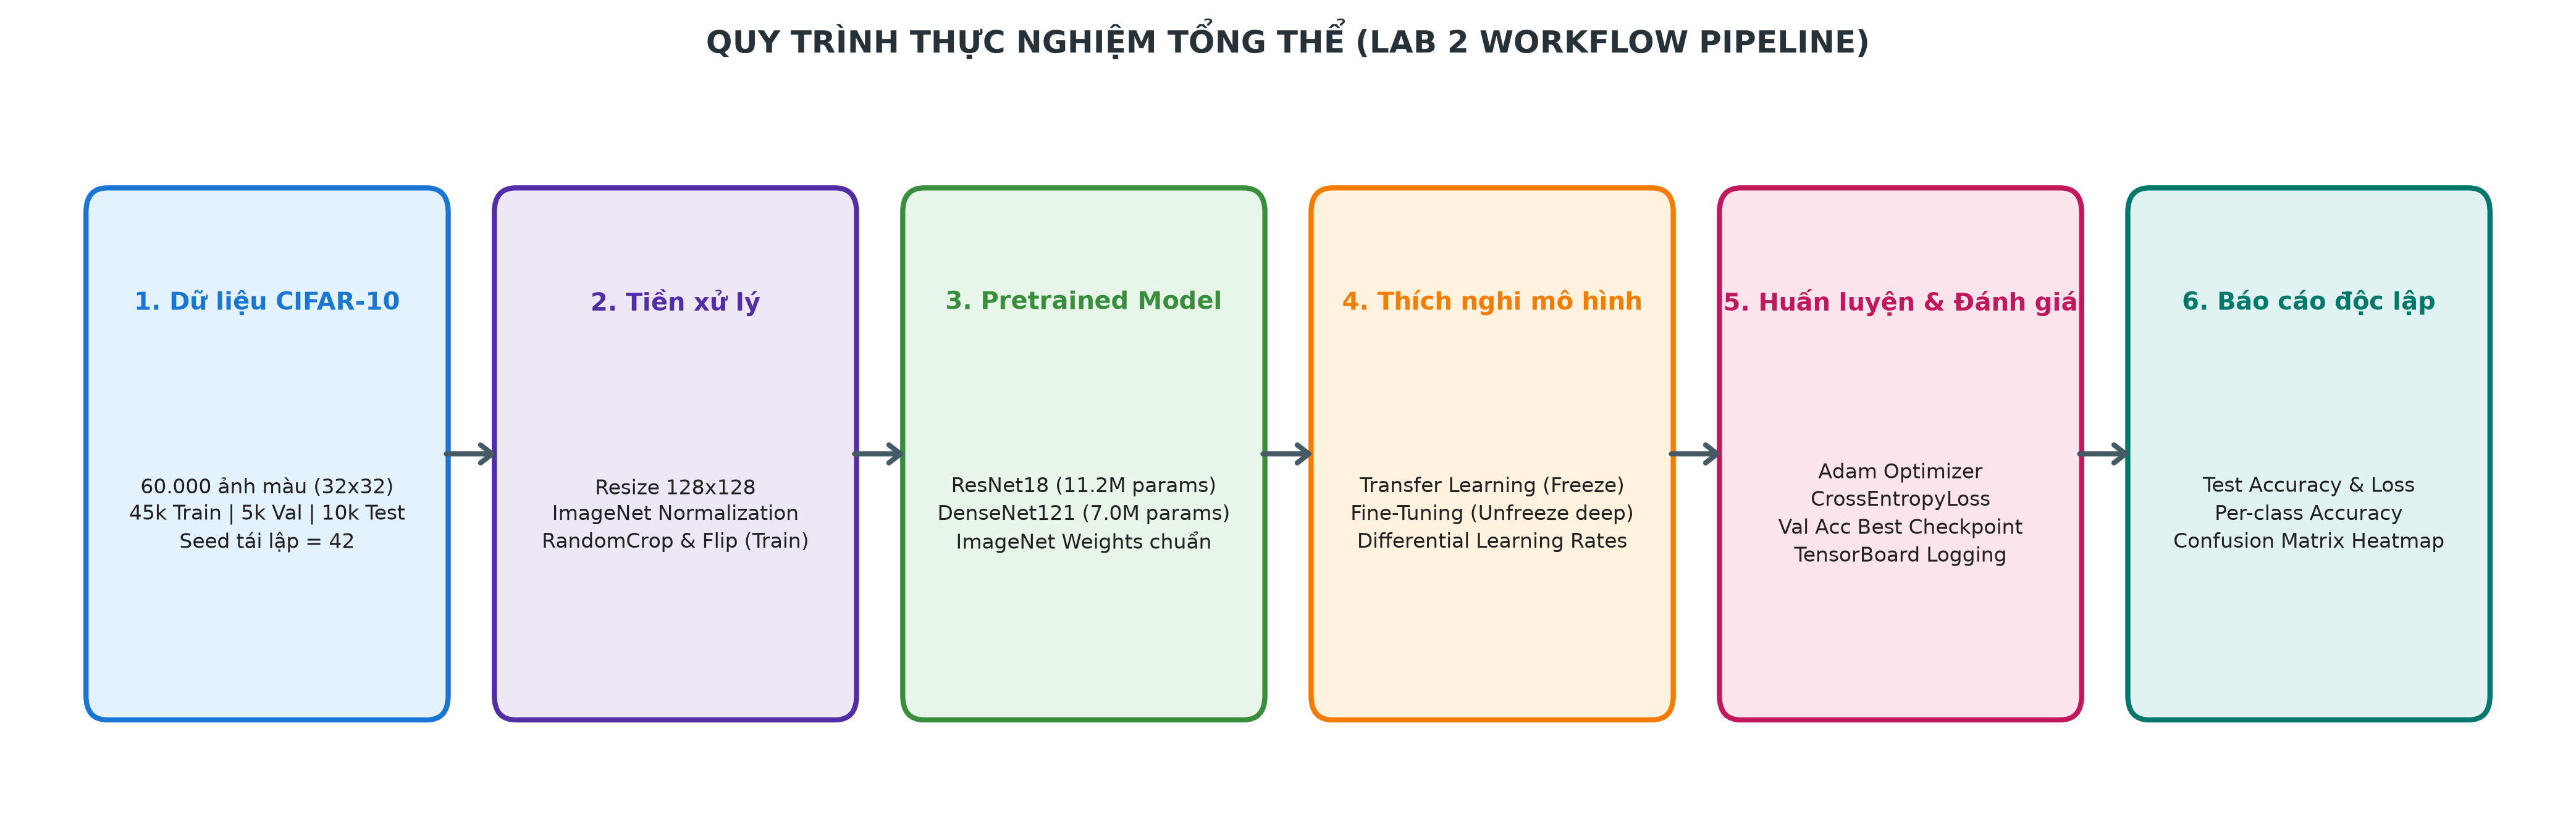

In [1]:
from IPython.display import Image, display
import os
fig_path = os.path.join(os.path.abspath(''), '..', 'docs', 'figures', 'pipeline_workflow.png')
if os.path.exists(fig_path):
    display(Image(filename=fig_path, width=900))
else:
    print('Hình chưa được tạo. Chạy: py scripts/generate_diagrams.py')

In [2]:
# Thiết lập đường dẫn thư mục gốc dự án độc lập với môi trường chạy
import os
import sys

current_path = os.path.abspath("")
while current_path != os.path.dirname(current_path):
    if os.path.exists(os.path.join(current_path, "src")) and os.path.exists(os.path.join(current_path, "configs")):
        break
    current_path = os.path.dirname(current_path)

PROJECT_ROOT = current_path
if os.path.join(PROJECT_ROOT, "src") not in sys.path:
    sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

# Chuyển working directory về gốc repository để các đường dẫn tương đối hoạt động chính xác
os.chdir(PROJECT_ROOT)
print(f"Project root xác định: {os.path.abspath('.')}")

Project root xác định: <PROJECT_ROOT>


In [3]:
# THAM SỐ ĐIỀU KHIỂN THỰC THI TRONG NOTEBOOK
# Đặt SMOKE_TEST = True để chạy kiểm thử nhanh luồng pipeline trên tập mẫu nhỏ
# Đặt SMOKE_TEST = False để chạy huấn luyện đầy đủ 5 epochs
SMOKE_TEST = True
EXPERIMENT_ID = "resnet18_transfer"

print(f"Cấu hình Notebook: SMOKE_TEST = {SMOKE_TEST} | EXPERIMENT_ID = '{EXPERIMENT_ID}'")

Cấu hình Notebook: SMOKE_TEST = True | EXPERIMENT_ID = 'resnet18_transfer'


## 1. Environment Setup (Slide 3)
Thiết lập môi trường phần mềm và phần cứng thực thi theo yêu cầu của đề bài:
- Đảm bảo tính tái lập (reproducibility) bằng cách cố định `seed` cho Python random, NumPy và PyTorch.
- Xác định thiết bị tính toán (`device`): mặc định CPU-first phù hợp với máy tính không có GPU rời.
- Kiểm tra phiên bản hệ điều hành, Python, PyTorch, Torchvision và TensorBoard.

In [4]:
import platform
import random
import numpy as np
import torch
import torchvision
import tensorboard
from lab2.utils import set_seed, get_device

print(f"Hệ điều hành: {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"TensorBoard: {tensorboard.__version__}")

device = get_device("cpu")
print(f"Thiết bị tính toán: {device} (CUDA khả dụng: {torch.cuda.is_available()})")

# Cố định hạt giống ngẫu nhiên để tái lập thực nghiệm
set_seed(42)
print("Đã thiết lập hạt giống ngẫu nhiên (seed=42) thành công.")

Hệ điều hành: Windows 11 (AMD64)
Python: 3.14.7
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
TensorBoard: 2.21.0
Thiết bị tính toán: cpu (CUDA khả dụng: False)
Đã thiết lập hạt giống ngẫu nhiên (seed=42) thành công.


## 2. Load a Pre-trained Model (Slide 20)
Theo Slide 20, ta nạp các mô hình kiến trúc sâu từ `torchvision.models` đi kèm bộ trọng số chuẩn được huấn luyện sẵn trên tập dữ liệu ImageNet (1.000 lớp, hơn 1,2 triệu ảnh) thông qua cú pháp chuẩn mới `weights=...DEFAULT`:
1. **ResNet-18** (`models.resnet18(weights=models.ResNet18_Weights.DEFAULT)`): Mạng dư học sâu với các kết nối tắt (residual skip-connections) giúp khắc phục triệt để hiện tượng suy biến gradient.
2. **DenseNet-121** (`models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)`): Mạng tích chập kết nối dày đặc, kết nối trực tiếp tất cả các tầng phía trước tới các tầng phía sau theo cơ chế ghép đặc trưng (feature reuse), giảm mạnh số lượng tham số cần thiết.

In [5]:
import torchvision.models as tv_models

print("Nạp mô hình ResNet-18 với ImageNet pre-trained weights:")
raw_resnet18 = tv_models.resnet18(weights=tv_models.ResNet18_Weights.DEFAULT)
print(f"-> Nạp thành công: {type(raw_resnet18).__name__}")

print("\nNạp mô hình DenseNet-121 với ImageNet pre-trained weights:")
raw_densenet121 = tv_models.densenet121(weights=tv_models.DenseNet121_Weights.DEFAULT)
print(f"-> Nạp thành công: {type(raw_densenet121).__name__}")

Nạp mô hình ResNet-18 với ImageNet pre-trained weights:
-> Nạp thành công: ResNet

Nạp mô hình DenseNet-121 với ImageNet pre-trained weights:


-> Nạp thành công: DenseNet


## 3. Explore the Model Architecture (Slide 3, 20)
Khảo sát kiến trúc mạng nhằm xác định cấu trúc các tầng và số lượng tham số trước khi sửa đổi:
- **ResNet-18:** Gồm tầng tích chập ban đầu `conv1`, lớp chuẩn hóa `bn1`, 4 cụm khối dư `layer1` đến `layer4`, tầng trung bình hóa toàn cục (Global Average Pooling) và lớp phân loại cuối cùng `fc` (512 chiều đầu vào, 1000 đầu ra ban đầu).
- **DenseNet-121:** Gồm cụm `features` chứa 4 khối dày đặc `denseblock1` đến `denseblock4` cùng 3 khối chuyển đổi `transition1` đến `transition3`, lớp chuẩn hóa cuối `norm5`, và lớp phân loại `classifier` (1024 chiều đầu vào, 1000 đầu ra ban đầu).
- Sử dụng hàm tiện ích `count_parameters` để kiểm đếm số tham số chi tiết.

In [6]:
from lab2.models import count_parameters

res_params = count_parameters(raw_resnet18)
dense_params = count_parameters(raw_densenet121)

print(f"{'Mô hình':<15} | {'Tổng tham số':<15} | {'Tầng cuối (Classifier Head)':<30}")
print("-" * 68)
print(f"{'ResNet-18':<15} | {res_params['total']:<15,} | {str(raw_resnet18.fc):<30}")
print(f"{'DenseNet-121':<15} | {dense_params['total']:<15,} | {str(raw_densenet121.classifier):<30}")

Mô hình         | Tổng tham số    | Tầng cuối (Classifier Head)   
--------------------------------------------------------------------
ResNet-18       | 11,689,512      | Linear(in_features=512, out_features=1000, bias=True)
DenseNet-121    | 7,978,856       | Linear(in_features=1024, out_features=1000, bias=True)


## 4. Adapt the Model for a Specific Task (Slide 20–21)
Để phân loại 10 lớp của CIFAR-10, ta thay thế lớp phân loại cuối cùng (Classifier Head) và áp dụng 2 chiến lược thích nghi khác nhau:
1. **Transfer Learning (Feature Extraction):**
   - Đóng băng toàn bộ các tầng trích xuất đặc trưng của backbone (`param.requires_grad = False`).
   - Khởi tạo mới lớp phân loại `model.fc` (ResNet18: 512 in / 10 out) hoặc `model.classifier` (DenseNet121: 1024 in / 10 out) với `requires_grad = True`.
2. **Fine-Tuning:**
   - Đóng băng các tầng đầu (trích xuất đặc trưng chung: biên, cạnh, màu sắc).
   - Mở khóa các khối tích chập sâu nhất (`layer4` ở ResNet18; `denseblock4` và `norm5` ở DenseNet121) cùng với classifier head mới để tinh chỉnh theo các đặc trưng ngữ nghĩa riêng của CIFAR-10.
   - Áp dụng **Differential Learning Rate** (tốc độ học backbone nhỏ hơn 10 lần so với head) để bảo vệ tri thức đã học khỏi hiện tượng quên thảm họa (catastrophic forgetting).

### Sơ đồ Khái niệm: Transfer Learning vs Fine-Tuning

Hình dưới đây phân biệt rõ hai chiến lược thích nghi mô hình về cơ chế đóng băng/mở khóa tham số và chiến lược tốc độ học vi phân (Differential Learning Rate).

*(Sơ đồ kiến trúc khái niệm — Không phải kết quả thực nghiệm)*

In [7]:
fig_path = os.path.join(os.path.abspath(''), '..', 'docs', 'figures', 'transfer_vs_finetune.png')
if os.path.exists(fig_path):
    display(Image(filename=fig_path, width=900))
else:
    print('Hình chưa được tạo. Chạy: py scripts/generate_diagrams.py')

Hình chưa được tạo. Chạy: py scripts/generate_diagrams.py


In [8]:
from lab2.models import build_model, count_parameters

exp_configs = [
    ("resnet18_transfer", "resnet18", "transfer"),
    ("resnet18_finetune", "resnet18", "finetune"),
    ("densenet121_transfer", "densenet121", "transfer"),
    ("densenet121_finetune", "densenet121", "finetune"),
]

print(f"{'Experiment ID':<24} | {'Model':<12} | {'Method':<10} | {'Total':<12} | {'Trainable':<12} | {'Trainable %'}")
print("-" * 85)

for exp_id, m_name, method in exp_configs:
    m = build_model(model_name=m_name, method=method, num_classes=10, pretrained=False)
    p = count_parameters(m)
    pct = (p['trainable'] / p['total']) * 100
    print(f"{exp_id:<24} | {m_name:<12} | {method:<10} | {p['total']:<12,} | {p['trainable']:<12,} | {pct:.2f}%")

Experiment ID            | Model        | Method     | Total        | Trainable    | Trainable %
-------------------------------------------------------------------------------------
resnet18_transfer        | resnet18     | transfer   | 11,181,642   | 5,130        | 0.05%


resnet18_finetune        | resnet18     | finetune   | 11,181,642   | 8,398,858    | 75.11%
densenet121_transfer     | densenet121  | transfer   | 6,964,106    | 10,250       | 0.15%


densenet121_finetune     | densenet121  | finetune   | 6,964,106    | 2,170,378    | 31.17%


### Biểu đồ So sánh Tham số Trainable vs Frozen

Biểu đồ cột dưới đây trực quan hóa tỷ lệ tham số được cập nhật trong quá trình huấn luyện so với tổng số tham số của mô hình. **Số liệu được đo trực tiếp từ `count_parameters()` trong `src/lab2/models.py` — không ước tính.**

*(Source-first: Dữ liệu trích từ `py scripts/inspect_models.py`)*

In [9]:
fig_path = os.path.join(os.path.abspath(''), '..', 'docs', 'figures', 'model_parameters_comparison.png')
if os.path.exists(fig_path):
    display(Image(filename=fig_path, width=800))
else:
    print('Hình chưa được tạo. Chạy: py scripts/generate_diagrams.py')

Hình chưa được tạo. Chạy: py scripts/generate_diagrams.py


## 5. Prepare the Data (Slide 4–5)
Chuẩn bị dữ liệu ảnh CIFAR-10:
- **Tiền xử lý (Data Transforms):**
  * Resize ảnh từ 32x32 lên 128x128 để phù hợp với trường tiếp nhận (receptive field) của các mạng học sâu nạp từ ImageNet.
  * Chuyển đổi tensor và chuẩn hóa ảnh (`Normalize`) bằng kỳ vọng và độ lệch chuẩn của ImageNet: `mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`.
- **Phân chia dữ liệu (Data Splitting):**
  * Tập Train: 45.000 mẫu.
  * Tập Validation: 5.000 mẫu (chia từ 50.000 mẫu train ban đầu với `seed=42`).
  * Tập Test: 10.000 mẫu giữ độc lập hoàn toàn để đánh giá không thiên vị.

Số lượng mẫu: Train=120 | Val=30 | Test=30
Danh sách 10 lớp: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


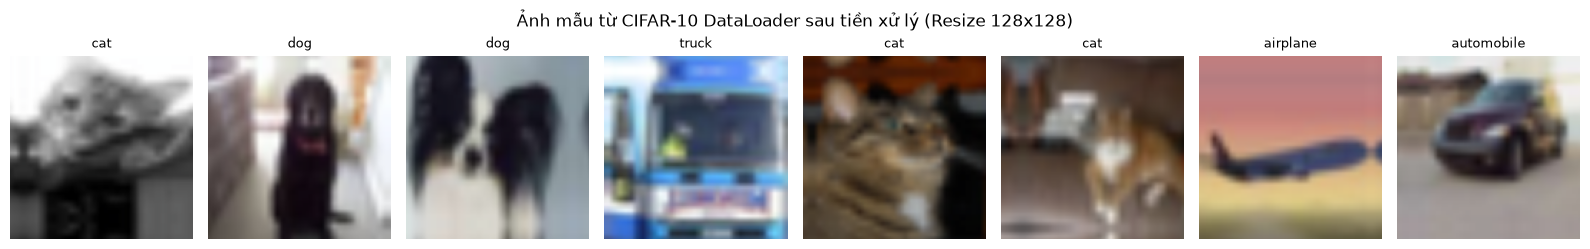

In [10]:
import matplotlib.pyplot as plt
from lab2.data import get_dataloaders

subset_size = 120 if SMOKE_TEST else None
train_loader, val_loader, test_loader, class_names = get_dataloaders(
    data_dir="./data",
    batch_size=16,
    val_split=0.1,
    seed=42,
    image_size=128,
    num_workers=0,
    subset_size=subset_size
)

print(f"Số lượng mẫu: Train={len(train_loader.dataset)} | Val={len(val_loader.dataset)} | Test={len(test_loader.dataset)}")
print(f"Danh sách 10 lớp: {class_names}")

# Hiển thị trực quan lưới 8 ảnh mẫu kèm nhãn
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(min(8, len(images))):
    img = images[i].numpy().transpose((1, 2, 0))
    img = np.clip(std * img + mean, 0, 1)  # Khôi phục màu sắc tự nhiên
    axes[i].imshow(img)
    axes[i].set_title(class_names[labels[i]], fontsize=9)
    axes[i].axis("off")
plt.suptitle("Ảnh mẫu từ CIFAR-10 DataLoader sau tiền xử lý (Resize 128x128)", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Train the Model (Slide 7–9)
Triển khai vòng lặp huấn luyện theo đúng 6 bước trong Slide 8–9:
1. `model.train()`: Đặt mô hình ở chế độ học (kích hoạt dropout và cập nhật batchnorm).
2. `optimizer.zero_grad()`: Xóa sạch gradient tích lũy từ bước trước.
3. `outputs = model(inputs)`: Lan truyền tiến tính phân phối logits.
4. `loss = criterion(outputs, labels)`: Tính độ mất mát với hàm CrossEntropyLoss.
5. `loss.backward()`: Lan truyền ngược tự động tính đạo hàm theo chuỗi quy tắc (Autograd).
6. `optimizer.step()`: Cập nhật trọng số của các tham số có `requires_grad=True`.

Bảng đối chiếu lý thuyết Slide 8–9 và mã nguồn trong `src/lab2/train.py`:
| Bước lý thuyết (Slide 8–9) | Dòng mã nguồn `src/lab2/train.py` | Mục đích kỹ thuật |
|:---|:---|:---|
| 1. Chế độ huấn luyện | `model.train()` | Bật chế độ huấn luyện cho các tầng |
| 2. Xóa gradient | `optimizer.zero_grad()` | Tránh cộng dồn gradient qua các batch |
| 3. Forward pass | `outputs = model(inputs)` | Tính đầu ra logits qua các tầng mạng |
| 4. Compute Loss | `loss = criterion(outputs, labels)` | Tính sai số phân loại giữa nhãn dự đoán và nhãn thực |
| 5. Backward pass | `loss.backward()` | Tự động tính đạo hàm theo chuỗi quy tắc (autograd) |
| 6. Optimizer step | `optimizer.step()` | Điều chỉnh các trọng số có `requires_grad=True` |

Lý do chọn Optimizer: Sử dụng **Adam** kết hợp với **Differential Learning Rates** cho bài toán fine-tuning vì Adam tự động điều chỉnh quán tính và tốc độ học theo từng tham số (adaptive learning rates), giúp việc huấn luyện trên CPU hội tụ ổn định và nhanh hơn so với SGD truyền thống.

In [11]:
import inspect
from lab2.train import train_one_epoch, run_training
from lab2.config import load_config
from lab2.tensorboard_logger import TensorBoardLogger

# Hiển thị mã nguồn thực tế của hàm train_one_epoch để đối chiếu với Slide 8-9
print("=== MÃ NGUỒN THỰC TẾ CỦA HÀM train_one_epoch (src/lab2/train.py) ===")
print(inspect.getsource(train_one_epoch))

# Thực thi huấn luyện theo chế độ SMOKE_TEST
overrides = {"epochs": 1, "batch_size": 16} if SMOKE_TEST else {}
cfg = load_config(EXPERIMENT_ID, overrides=overrides)
model = build_model(cfg.model_name, method=cfg.method, num_classes=cfg.num_classes, pretrained=True)

logger = TensorBoardLogger(os.path.join(cfg.runs_dir, f"{cfg.name}_notebook"))
try:
    print(f"\nBắt đầu huấn luyện mô hình: {cfg.name} (Epochs={cfg.epochs}, Device={cfg.device})")
    results = run_training(
        cfg=cfg,
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        logger=logger
    )
finally:
    logger.close()

=== MÃ NGUỒN THỰC TẾ CỦA HÀM train_one_epoch (src/lab2/train.py) ===
def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device
) -> Tuple[float, float]:
    """
    Executes one training epoch following Slides 8 & 9.
    Returns: (epoch_loss, epoch_accuracy_percent)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (data, labels) in enumerate(dataloader):
        data = data.to(device)
        labels = labels.to(device)

        # 1. Zero gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(data)

        # 3. Compute loss
        loss = criterion(outputs, labels)

        # 4. Backward pass
        loss.backward()

        # 5. Optimization step
        optimizer.step()

        # Accumulate metrics
        batch_size = data.size(0)
        running_loss += loss.item() * batch_size
        _, predicted = o


Starting Experiment: resnet18_transfer
Model: resnet18 | Method: transfer
Epochs: 1 | Batch Size: 16 | Device: cpu


Epoch [01/01] Time: 00m 01s | Train Loss: 2.4299 - Acc: 15.83% | Val Loss: 2.1218 - Acc: 26.67% * [Best]

Training completed in 00m 01s.
Best checkpoint at epoch 1 with val_acc: 26.67
Saved: ./checkpoints\resnet18_transfer_best.pth


## 7. Evaluate the Model (Slide 10–11)
Đánh giá mô hình trên tập kiểm thử độc lập (Test Set):
- Đặt mô hình ở chế độ đánh giá: `model.eval()`.
- Tắt tính toán gradient để tối ưu hóa bộ nhớ RAM và tốc độ: `with torch.no_grad():`.
- Đánh giá checkpoint tốt nhất (`*_best.pth`) được lựa chọn dựa trên chỉ số validation accuracy cao nhất.
- Đo lường: Test Loss, Test Accuracy, Độ chính xác trên từng lớp (Per-class Accuracy) và biểu diễn qua Ma trận nhầm lẫn (Confusion Matrix).

In [12]:
from lab2.evaluate import evaluate_checkpoint_file

best_ckpt = results["best_checkpoint_path"]
if os.path.exists(best_ckpt):
    print(f"Đánh giá checkpoint tốt nhất: {best_ckpt}")
    test_res = evaluate_checkpoint_file(
        checkpoint_path=best_ckpt,
        test_loader=test_loader,
        class_names=class_names,
        outputs_dir="./outputs"
    )
    print(f"\nKết quả kiểm thử trên Test Set:")
    print(f"- Test Loss: {test_res['test_loss']:.4f}")
    print(f"- Test Accuracy: {test_res['test_accuracy']:.2f}%")
    print(f"- Per-class Accuracy: {test_res['per_class_accuracy']}")
else:
    print(f"Không tìm thấy checkpoint {best_ckpt}. Vui lòng chạy huấn luyện trước.")

Đánh giá checkpoint tốt nhất: ./checkpoints\resnet18_transfer_best.pth



Evaluation Results for [resnet18_transfer]:
Test Loss: 2.1330
Test Accuracy: 16.67%
Metrics saved to: ./outputs\metrics\resnet18_transfer_test_metrics.json
Figure saved to: ./outputs\figures\resnet18_transfer_confusion_matrix.png

Kết quả kiểm thử trên Test Set:
- Test Loss: 2.1330
- Test Accuracy: 16.67%
- Per-class Accuracy: {'airplane': 0.0, 'automobile': 0.0, 'bird': 0.0, 'cat': 50.0, 'deer': 0.0, 'dog': 33.33, 'frog': 20.0, 'horse': 33.33, 'ship': 0.0, 'truck': 25.0}


## 8. Exercise 1 — Different Pre-trained Models (Slide 23)
So sánh đối chứng các kiến trúc mô hình học sâu khác nhau:
- **ResNet18** (Residual Networks) vs. **DenseNet121** (Dense Convolutional Networks).
- Đọc bảng số liệu so sánh trực tiếp từ file `summary.csv` được sinh ra tự động.
- **Giải thích kỹ thuật về việc không đưa VGG16 vào thực nghiệm chính thức:**
  * Mặc dù đề bài ghi *"VGG, DenseNet, etc."*, VGG16 có kích thước mô hình cực lớn (138 triệu tham số, trong đó riêng 3 tầng FC chiếm hơn 120 triệu tham số).
  * Trên phần cứng CPU Intel Core i5 không có card đồ họa GPU, VGG16 tiêu tốn tài nguyên bộ nhớ rất lớn và tốc độ tính toán chậm hơn từ 4-6 lần so với ResNet18 và DenseNet121, đồng thời dễ gặp hiện tượng quá khớp (overfitting) trên tập dữ liệu ảnh kích thước nhỏ như CIFAR-10. DenseNet121 đã đại diện xuất sắc cho họ kiến trúc cải tiến sâu với cơ chế tái sử dụng đặc trưng hiệu quả.

In [13]:
import pandas as pd

summary_csv_path = "./outputs/metrics/summary.csv"
if os.path.exists(summary_csv_path):
    df_summary = pd.read_csv(summary_csv_path)
    core_df = df_summary[df_summary["Experiment ID"].isin([
        "resnet18_transfer", "resnet18_finetune", "densenet121_transfer", "densenet121_finetune"
    ])]
    display(core_df)
else:
    print("File outputs/metrics/summary.csv chưa tồn tại.")
    print("Vui lòng thực hiện chạy huấn luyện đầy đủ ở Phase 5 để sinh số liệu thật.")

File outputs/metrics/summary.csv chưa tồn tại.
Vui lòng thực hiện chạy huấn luyện đầy đủ ở Phase 5 để sinh số liệu thật.


## 9. Exercise 2 — Hyperparameter Adjustment (Slide 23)
Thực nghiệm điều chỉnh các siêu tham số (Hyperparameter Adjustment):
- Đối tượng thử nghiệm: `resnet18_transfer` (cấu hình cơ sở nhẹ nhất, kiểm soát tốt các biến số).
- Tiến hành 2 biến thể thực nghiệm, mỗi biến thể **chỉ thay đổi duy nhất một yếu tố** để bảo đảm tính khoa học:
  1. `resnet18_transfer_lr1e4`: Giảm Learning Rate xuống $10^{-4}$ (so với gốc $10^{-3}$).
  2. `resnet18_transfer_bs32`: Tăng Batch Size lên $32$ (so với gốc $16$).
- Biến kiểm soát: Giữ nguyên cố định hoàn toàn `seed=42`, phân chia tập dữ liệu 45k/5k/10k, thuật toán tối ưu Adam, hàm mất mát CrossEntropy, và số lượng epoch.

> **Lưu ý khoa học:** Kết quả thực nghiệm chỉ đo trên một lần chạy duy nhất với một seed ngẫu nhiên (`seed=42`). Mọi sự chênh lệch nhỏ về độ chính xác có thể nằm trong khoảng dao động ngẫu nhiên, không thể kết luận khái quát tuyệt đối nếu chưa chạy lặp lại trên nhiều seed.

In [14]:
if os.path.exists(summary_csv_path):
    df_summary = pd.read_csv(summary_csv_path)
    hparam_df = df_summary[df_summary["Experiment ID"].isin([
        "resnet18_transfer", "resnet18_transfer_lr1e4", "resnet18_transfer_bs32"
    ])]
    display(hparam_df)
else:
    print("Chưa có file kết quả summary.csv. Khi chạy xong Phase 5, bảng so sánh siêu tham số sẽ hiển thị tại đây.")

Chưa có file kết quả summary.csv. Khi chạy xong Phase 5, bảng so sánh siêu tham số sẽ hiển thị tại đây.


## 10. Exercise 3 — TensorBoard Monitoring (Slide 13–15)
Giám sát trực quan toàn bộ tiến trình huấn luyện bằng TensorBoard:
- Lệnh khởi chạy TensorBoard từ terminal:
  ```bash
  tensorboard --logdir=runs
  ```
  Truy cập qua trình duyệt tại địa chỉ: `http://localhost:6006/`
- Các tab giám sát chính:
  * **Scalars:** Theo dõi đường cong `Loss/train`, `Loss/val`, `Accuracy/train`, `Accuracy/val` qua từng epoch để phát hiện sớm quá khớp (overfitting).
  * **Graphs:** Kiểm tra trực quan đồ thị tính toán luồng tensor qua các tầng của mô hình.
  * **Images:** Giám sát lưới ảnh đầu vào sau tiền xử lý để xác thực phép chuẩn hóa và biến đổi hình học.
  * **Histograms:** Theo dõi sự biến thiên phân phối trọng số và gradient của từng lớp qua thời gian.

In [15]:
import glob
from IPython.display import Image, display

tb_figures = [
    ("docs/figures/tensorboard_scalars.png", "Biểu đồ Scalars (Loss và Accuracy theo Epoch)"),
    ("docs/figures/tensorboard_graph.png", "Đồ thị kiến trúc mạng (Computational Graph)"),
    ("docs/figures/tensorboard_images.png", "Lưới ảnh đầu vào (Images tab)"),
    ("docs/figures/tensorboard_histograms.png", "Phân phối trọng số mô hình (Histograms tab)")
]

found_fig = False
for path, desc in tb_figures:
    if os.path.exists(path):
        print(f"=== {desc} ===")
        display(Image(filename=path))
        found_fig = True

if not found_fig:
    print("Chưa tìm thấy ảnh chụp TensorBoard trong thư mục docs/figures/.")
    print("Sau khi chạy full huấn luyện ở Phase 5, nhóm sinh viên sẽ chụp màn hình TensorBoard thật và lưu vào docs/figures/.")

Chưa tìm thấy ảnh chụp TensorBoard trong thư mục docs/figures/.
Sau khi chạy full huấn luyện ở Phase 5, nhóm sinh viên sẽ chụp màn hình TensorBoard thật và lưu vào docs/figures/.


## 11. Giới hạn Kỹ thuật và Hướng Phát triển
### Giới hạn kỹ thuật đã phát hiện qua đo đạc thực nghiệm (Phase 6):
1. **Hành vi BatchNorm trong Backbone đóng băng:** Khi đóng băng backbone bằng `requires_grad=False`, vòng lặp huấn luyện gọi `model.train()`. Phép đo thực nghiệm tại Phase 6 chứng minh rằng toàn bộ 20 lớp BatchNorm (60 buffers) của ResNet18 và 121 lớp BatchNorm (363 buffers) của DenseNet121 **vẫn tiếp tục cập nhật `running_mean` và `running_var`** theo từng batch dữ liệu mới của CIFAR-10.
2. **Ràng buộc phần cứng CPU:** Thiếu vắng tăng tốc phần cứng CUDA khiến thời gian huấn luyện 5 epochs trên tập 45.000 mẫu kéo dài đáng kể.
3. **Phóng đại kích thước ảnh (Interpolation artifacts):** Phóng to ảnh từ 32x32 lên 128x128 có thể gây mờ chi tiết cạnh sắc nét.
4. **Giới hạn một seed duy nhất:** Kết quả thực nghiệm đo trên một hạt giống ngẫu nhiên (`seed=42`).

### Hướng phát triển và cải tiến:
1. Đặt tường minh các lớp BatchNorm đóng băng ở chế độ `eval` (`module.eval()`) trong suốt quá trình fine-tuning để bảo toàn thống kê đặc trưng ImageNet.
2. Thử nghiệm bộ điều chỉnh tốc độ học (Learning Rate Scheduler như `CosineAnnealingLR`).
3. Chạy thực nghiệm trên nhiều seed độc lập (ví dụ 3-5 seeds) và báo cáo giá trị trung bình kèm độ lệch chuẩn.
4. [SV điền nhận xét và đề xuất cá nhân]

## 12. Tài liệu Tham khảo
1. PhD. Nguyễn Thị Khánh Tiên, *Chương 3 — Training Deep Neural Networks*, Bài giảng môn Deep Learning, Trường ĐH Giao thông Vận tải TP.HCM.
2. PyTorch Team, *Transfer Learning for Computer Vision Tutorial*, https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html.
3. PyTorch Team, *Torchvision Models Documentation*, https://pytorch.org/vision/stable/models.html.
4. Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016.
5. Gao Huang, Zhuang Liu, Laurens van der Maaten, Kilian Q. Weinberger, *Densely Connected Convolutional Networks*, CVPR 2017.